# Bike Sharing Project

Your task is to **predict how many bikes are rented in an hour** in the Capital Bikeshare system of Washington, D.C., and to find out how far **ensemble methods** improve on a single decision tree and on a linear model. In the project you combine everything you learned this week, from decision trees to boosting, voting and stacking, into one complete analysis.

The task below follows the steps of a machine learning project, in a single pass:

![The project in one pass, from top to bottom: 1. goal and metric, 2. get the data, 3. a train-test split into training data and locked test data. Steps 4 and 5 (explore, baselines) use only the training data. Steps 6 and 7 form the model selection loop: feature engineering, set hyperparameters, train model(s) and calculate the cross-validation score, then repeat. In step 8, the test data is unlocked, the models are scored on the test set and the hours with the largest errors are examined](assets/bike_sharing_project_workflow.png)

> [!NOTE]
> **AI reference solution.** This notebook is a complete solution written with Claude, for comparison. My own work is in [01_bike_sharing_project.ipynb](01_bike_sharing_project.ipynb).

# The Business Problem

The operations team of Capital Bikeshare plans its work hour by hour: how many bikes have to be available, how many trucks move bikes between stations, and how many staff are on duty. To plan, they need to know **how many bikes are rented in an hour under given conditions**: the time of day, the type of day, the season and the weather. A Tuesday at 17:00 in summer needs very different planning from a rainy Sunday morning in January.

Your model answers this question: given the conditions of an hour, it predicts its rentals. The more accurate it is, the better the team can plan, so you compare several models and choose the best one. At the end, you look at **where the model makes its biggest mistakes**, so that the team knows when they can trust its numbers and when not.

The model describes typical hours under given conditions; it is not used to forecast particular future dates. The hours you hold back as a test set can therefore be drawn **at random** from the whole period. A forecast would be a different problem: there the model has to predict hours that come after everything it was trained on, so the test set would have to be the most recent hours.

# Data Description

The data covers **two years, October 2024 to September 2026**, and ships with this repository as one table, `data/bike_sharing.csv`, with **one row per hour**. It combines three sources:

- the number of bikes rented in each hour, from the trip records that [Capital Bikeshare](https://capitalbikeshare.com/system-data) publishes. Every trip is counted in the hour in which it started;
- the weather in central Washington, D.C. in each hour, from the [Open-Meteo](https://open-meteo.com/) historical weather archive;
- the public holidays of Washington, D.C.

| Column | Source | Description |
| :-- | :-- | :-- |
| `datetime` | | start of the hour, local time in Washington, D.C. |
| `casual` | rentals | rentals by casual riders, who pay per ride or per day |
| `member` | rentals | rentals by members with an annual or monthly membership |
| `rentals` | rentals | total number of rentals in the hour, **the prediction target** |
| `temperature` | weather | air temperature in °C |
| `feels_like` | weather | apparent ("feels like") temperature in °C, which accounts for wind and humidity |
| `humidity` | weather | relative humidity in % |
| `precipitation` | weather | rain and snow in the hour, in mm of water |
| `snowfall` | weather | snowfall in the hour, in cm |
| `wind_speed` | weather | wind speed in km/h |
| `cloud_cover` | weather | share of the sky covered by clouds, in % |
| `weather_code` | weather | type of weather as a [WMO code](https://open-meteo.com/en/docs/historical-weather-api): 0 clear, 1 to 3 partly cloudy to overcast, 51 to 55 drizzle, 61 to 65 rain (light to heavy), 71 to 75 snow (light to heavy) |
| `holiday` | holidays | name of the public holiday on that day, empty on all other days |

Rentals data © Capital Bikeshare, used under the [Capital Bikeshare Data License Agreement](https://capitalbikeshare.com/data-license-agreement). Weather data by [Open-Meteo.com](https://open-meteo.com/), licensed [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

## Task

1. **Set your goal.** Decide which metric you use to judge the model, and explain why. Think about what the operations team needs to read from it.
2. **Get the data.** Load `data/bike_sharing.csv`, and take a first look at its size and columns. Turn `datetime` into a date type, so that you can extract the hour, the weekday or the month from it later.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `rentals` column. In step 7, cross-validation on the training set takes the place of a validation set. Do not look at `df_test` until step 8.
4. **Explore the training set.** How do the rentals change over the day, and is that pattern the same on working days, weekends and holidays? How do the weather columns relate to the rentals? Which columns contain the same information? Check every column carefully: **would you know its value for an hour without having counted that hour's rentals?**

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, new columns such as the hour of the day or a flag for working days that you extract from `datetime` and `holiday`, and every column you drop. Put these changes into a function, so that you can call the same function on the test set. Transformations inside your `Pipeline` (scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

5. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your models have to beat:
    - a **mean baseline** with [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html), which predicts the mean number of rentals of the training set for every hour, and
    - a **rule-based baseline** built from what you found in step 4, that a person could calculate by hand. Learn the values of the rule on the training data.
6. **Train a linear model and a single decision tree.** Train a regularised linear model, for example `Ridge`, in a `Pipeline` with the preprocessing it needs, and a `DecisionTreeRegressor`. Compare them with cross-validation: which one handles the pattern over the day better, and why? Does the tree need the same preprocessing as the linear model?
7. **Build, tune and compare ensembles with cross-validation.** Train at least:
    - a **random forest** (`RandomForestRegressor`),
    - a **gradient boosting model**, for example `XGBRegressor` or `CatBoostRegressor`: for a number, use the regressor and a regression metric. CatBoost can treat columns as categories itself (`cat_features`): find out whether that helps here,
    - and a **combination of models** with `VotingRegressor` or `StackingRegressor`.

    Tune at least one of the models with `RandomizedSearchCV` (or `GridSearchCV`), and choose the best model by its cross-validated score. **Save every model in its own variable** (and the values of your rule), so that you can evaluate all of them in the last step.
8. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the changes you made by hand to the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric, including both baselines, and collect them in **one table**: one row per model, with columns for the training and the test scores. Compare the models: which ones beat the baselines, how much did each step from the linear model to the ensembles gain, and how large is the difference between training and test scores?

    Finally, find out **where your best model makes its biggest mistakes**, so that the operations team knows when to trust it:
    1. **Calculate the residuals** of the test hours: actual rentals minus predicted rentals. A large positive residual means the model predicted far too few rentals, a large negative one far too many. Use only the test hours: the model has seen the training hours, so its errors there are too small to tell you anything.
    2. **Plot the residuals**: a scatter plot of the residuals against the predicted rentals, with a line at 0, and the size of the residuals by hour of the day (for example a box plot). Where does the model make its largest errors, and do the errors grow with the number of rentals?
    3. **Compare predicted and actual rentals over the day**: plot the mean actual and the mean predicted rentals for each hour of the day, separately for working days and weekends. Does the model reproduce the daily pattern you found in step 4? At which hours does it predict too many or too few rentals on average?
    4. **List the hours with the biggest mistakes**: the 10 hours with the largest positive and the 10 with the largest negative residuals, with their date, time and weather.

> [!TIP]
> If you use `CatBoostRegressor` with `cat_features` inside `cross_val_score` or a search, pass `cat_features` to `.fit()` instead of the constructor (for example `cross_val_score(..., params={"cat_features": [...]})`): set in the constructor, it breaks the copying of the model that cross-validation does.

In [1]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

## Step 1 – Goal and metric

**Main metric: RMSE (root mean squared error), in bikes per hour.**

The operations team plans bikes, trucks and staff hour by hour. RMSE is in the same unit as the target (bikes), so they can read it directly. Because it squares the errors before averaging, a few big misses weigh much more than many small ones, and a big miss in a busy hour (e.g. no bikes at 17:00 rush hour) costs the team more than several small misses.

I also report two more metrics for context:
- **MAE** (mean absolute error): the typical error in bikes, easy to explain. If RMSE is much larger than MAE, the model is mostly fine but sometimes misses very badly (a few large errors).
- **R²**: how much better the model is than always predicting the mean (1 = perfect, 0 = no better than the mean). It has no unit, so it is useful for comparing models but not for planning.

## Step 2 – Get the data

Load the table and take a first look. `datetime` is read from the CSV as text, so it is converted to a real date type. Only then can `.dt.hour`, `.dt.dayofweek` or `.dt.month` be used later.

Converting the type is allowed before the split: it only changes the format and learns nothing from the data.

In [2]:
# loading the dataset
df = pd.read_csv('data/bike_sharing.csv')

# converting the 'datetime' column to datetime type
df['datetime'] = pd.to_datetime(df['datetime'])

print(f"Dataset shape: {df.shape}")
print(df.dtypes)
df.head()

Dataset shape: (17520, 13)
datetime         datetime64[us]
casual                    int64
member                    int64
rentals                   int64
temperature             float64
feels_like              float64
humidity                  int64
precipitation           float64
snowfall                float64
wind_speed              float64
cloud_cover               int64
weather_code              int64
holiday                     str
dtype: object


,datetime,casual,member,rentals,temperature,feels_like,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,holiday
0,2024-10-01 00:00:00,47,89,136,18.1,19.5,96,0.2,0.0,8.6,100,51,NaN
1,2024-10-01 01:00:00,18,30,48,18.2,19.6,96,0.1,0.0,8.9,100,51,NaN
2,2024-10-01 02:00:00,14,17,31,18.2,19.2,94,0.0,0.0,10.3,100,3,NaN
3,2024-10-01 03:00:00,6,9,15,17.9,18.6,93,0.0,0.0,11.7,100,3,NaN
4,2024-10-01 04:00:00,7,20,27,17.6,18.1,93,0.1,0.0,12.4,100,51,NaN


**Check:** October 2024 to September 2026 is 730 days (no 29 February in 2025 or 2026), and 730 × 24 hours = **17,520 rows**, which matches the shape. There is one row per hour, with no gaps, and the 13 columns match the data description.

## Step 3 – Split into training and test set

- **Random split:** the model describes *typical* hours under given conditions; it does not forecast future dates (see the business problem). So the test hours can be drawn at random from the whole period. For a forecast, the test set would have to be the most recent hours instead.
- **The whole DataFrame is split**, so the features and `rentals` stay together. `X` and `y` are separated later.
- `test_size=0.2`: 20 % (≈ 3,500 hours) for the final test, 80 % for training.
- `random_state=42`: the same split every time the notebook runs.

From here on, everything is done on `df_train` only. `df_test` stays locked until step 8.

In [3]:
# splitting train and test data
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

print(f"train: {df_train.shape}")
print(f"test:  {df_test.shape}")

train: (14016, 13)
test:  (3504, 13)


## Step 4 – Explore the training set

### 4a. Data quality

Checks for missing values, duplicates and impossible values are done **after** the split, on the training set only. Every decision that learns something from the data (how to fill missing values, which outliers to remove, …) must not be influenced by the test set, otherwise the test score looks better than it really is (leakage).

**Missing values**

In [4]:
df_train.isna().sum()

datetime             0
casual               0
member               0
rentals              0
temperature          0
feels_like           0
humidity             0
precipitation        0
snowfall             0
wind_speed           0
cloud_cover          0
weather_code         0
holiday          13550
dtype: int64

Only `holiday` has missing values (13,550 of 14,016 hours). Let's look at the values it does have:

In [5]:
# check the distribution of the 'holiday' column in the training dataset
df_train["holiday"].value_counts()

holiday
Labor Day                               43
Washington's Birthday                   42
New Year's Day                          41
Juneteenth National Independence Day    40
Thanksgiving Day                        39
Independence Day                        39
Veterans Day                            38
Memorial Day                            38
DC Emancipation Day                     38
Christmas Day                           38
Columbus Day                            36
Birthday of Martin Luther King, Jr.     34
Name: count, dtype: int64

**Finding: `NaN` in `holiday` is not missing data; it means "this hour is not on a public holiday".** When there is a holiday, the column holds its name (e.g. "Christmas Day"). 14,016 − 13,550 = 466 holiday hours ≈ 12 holidays × 2 years × 24 hours × 80 % in train, so it fits.

A missing value can mean two different things:

| Kind | Meaning | What to do | Example |
|---|---|---|---|
| Not applicable | the thing didn't happen or doesn't exist | turn it into a 0/1 flag; don't fill it with an average | `holiday` here, `yr_renovated` in King County |
| Truly unknown | there should be a value, but it was not recorded | fill it in (median, most frequent, …) or drop the row | a broken weather sensor |

**Decision: use a flag `is_holiday` (1 = holiday, 0 = not) instead of the holiday name.**
Each holiday name appears on only 2 days in the whole dataset (48 hours, ~38 of them in train). One-hot encoding 12 names would let the model learn those few days by heart (e.g. "it rained on that particular Christmas"), which is overfitting. The flag pools all ~466 holiday hours into one pattern, and month and weekday features will already tell the model much of what the name says.

*Possible extra, if there is time:* add the holiday name as a feature and compare the cross-validated RMSE in step 7. Keep it only if it improves.

**Duplicates**

`df_train.duplicated()` only finds rows where **all 13 columns** are identical. Two rows for the same hour with slightly different numbers would not be found that way, so the `datetime` column is checked on its own too.

In [6]:
# check for fully identical rows in the training dataset
df_train.duplicated().sum()

np.int64(0)

In [7]:
# check for duplicate timestamps in the training dataset
df_train['datetime'].duplicated().sum()

np.int64(0)

**Open question: daylight saving time.** `datetime` is in local time, and Washington, D.C. has daylight saving time. Each spring one hour is skipped (2:00 → 3:00), and each autumn one hour happens twice. Still, there are exactly 17,520 rows and no duplicate timestamps. How did the data handle that?

Look at the night the clocks went forward (9 March 2025). This is only a check, not a modelling decision, so looking at `df` here is fine.

In [8]:
# the hour 02:00 did not exist on the clock that night - what do its rentals show?
df[df["datetime"].dt.strftime("%Y-%m-%d") == "2025-03-09"][["datetime", "rentals"]].head(6)

,datetime,rentals
3816,2025-03-09 00:00:00,309
3817,2025-03-09 01:00:00,214
3818,2025-03-09 02:00:00,0
3819,2025-03-09 03:00:00,155
3820,2025-03-09 04:00:00,61
3821,2025-03-09 05:00:00,54


**Answer:** the hour 02:00 on 9 March 2025 exists in the table, but `casual`, `member` and `rentals` are all **0**, while the weather columns are filled in. It is the same on 8 March 2026. These two rows are the only hours with 0 rentals in the whole dataset; even a snowy night at 4:00 has some rides. So the data was built on a regular grid of 24 hours per day, and the hour that never happened on the clock got 0 rentals.

In autumn (3 November 2024, 2 November 2025), 01:00 happens twice. There are no duplicate rows, so both hours were **added together into one row**: rentals rise from 00:00 to 01:00 on those nights (e.g. 460 → 645), where they normally fall after midnight.

**Decision:**
- **Drop the two spring rows.** The 0 does not mean "nobody rode"; the hour did not exist, and keeping it would teach the model something false about 2:00 at night. The rows are found by their **date and time** (second Sunday of March, 02:00), not with `rentals == 0`: on new data the rentals are not known in advance, so the rule must not use the target.
- **Keep the two autumn rows.** They are real hours, only two of them added together. 2 rows of 17,520 barely affect the model; they are worth checking in step 8.

**Impossible values**

Look for negative numbers, humidity above 100 %, a cloud cover outside 0–100, and similar.

In [9]:
df_train.describe().T

,count,mean,min,25%,50%,75%,max,std
datetime,14016,2025-10-01 05:16:10.119863,2024-10-01 00:00:00,2025-04-01 09:45:00,2025-10-01 01:30:00,2026-04-02 05:15:00,2026-09-30 23:00:00,NaN
casual,14016.0,218.758134,0.0,47.0,158.0,320.0,1593.0,211.07215
member,14016.0,534.566781,0.0,134.0,464.0,813.0,2465.0,449.294812
rentals,14016.0,753.324914,0.0,186.75,639.0,1142.0,3188.0,636.260286
temperature,14016.0,14.102775,-15.0,5.8,15.3,22.7,39.7,10.512618
feels_like,14016.0,12.917559,-19.7,2.3,13.5,24.1,43.9,13.20581
humidity,14016.0,67.78232,15.0,53.0,68.0,84.0,100.0,19.018021
precipitation,14016.0,0.136173,0.0,0.0,0.0,0.0,13.6,0.643516
snowfall,14016.0,0.00442,0.0,0.0,0.0,0.0,2.03,0.064462
wind_speed,14016.0,10.127811,0.0,6.0,9.0,13.3,39.7,5.60369


**Finding:** no impossible values. Rentals are 0 or more, humidity and cloud cover stay within 0–100 %, temperatures between −15 °C and 40 °C are plausible for Washington, D.C., and precipitation and snowfall are 0 in most hours (median 0), with a few wet hours up to 13.6 mm.

### 4b. Rentals over the day

How do the rentals change over the day, and is that pattern the same on working days, weekends and holidays?

The exploration works on a copy (`eda`), so `df_train` stays clean. The real features are made later in `prepare()`, so that they also get applied to the test set.

day_type
working day    9535
weekend        4015
holiday         466
Name: count, dtype: int64


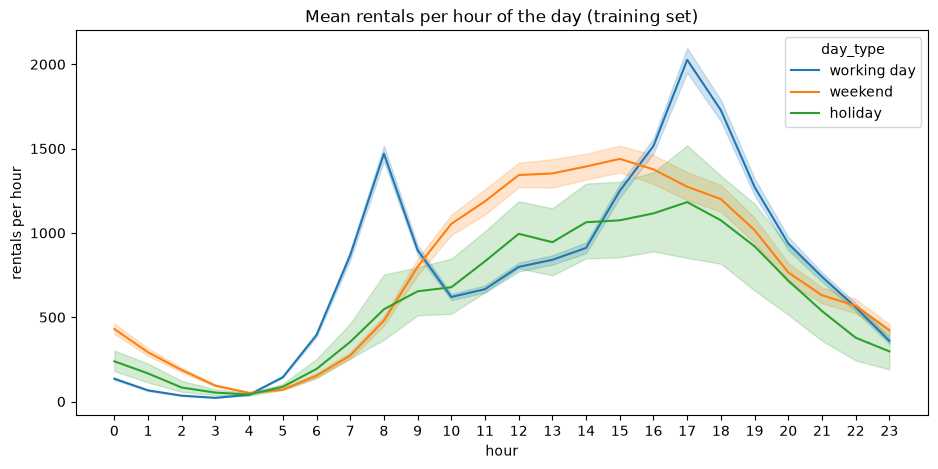

In [10]:
eda = df_train.copy()
eda["hour"] = eda["datetime"].dt.hour
eda["weekday"] = eda["datetime"].dt.dayofweek   # 0 = Monday, 6 = Sunday

# three types of day: a holiday counts as a holiday even if it falls on a weekday
eda["day_type"] = np.where(eda["holiday"].notna(), "holiday",
                  np.where(eda["weekday"] >= 5, "weekend", "working day"))

print(eda["day_type"].value_counts())

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=eda, x="hour", y="rentals", hue="day_type",
             hue_order=["working day", "weekend", "holiday"], ax=ax)
ax.set_title("Mean rentals per hour of the day (training set)")
ax.set_xticks(range(0, 24))
ax.set_ylabel("rentals per hour")
plt.show()

**Finding:** the type of day changes the **shape** of the day, not just its level.
- **Working days** have two sharp peaks: the morning commute at **8:00** (≈ 1,450 rentals) and the evening commute at **17:00–18:00** (≈ 2,000, the busiest hours of all), with a dip around 10:00.
- **Weekends** have no commuting peaks; rentals rise slowly to one broad hump in the afternoon (≈ 1,400 around 12:00–16:00). Late at night (0:00–2:00), weekends are busier than working days: people go out on Friday and Saturday night.
- **Holidays** look like weekends, at a somewhat lower level, and with a wide confidence band, because there are only 466 holiday hours (≈ 20 days). So a holiday flag is needed, and a model has to learn **a different daily curve per type of day**.

### 4c. Weather and rentals

The weather is compared in **daytime hours only (7:00–20:00)**: at night rentals are low whatever the weather, so night hours would distort the comparison (confounding by the hour of the day).

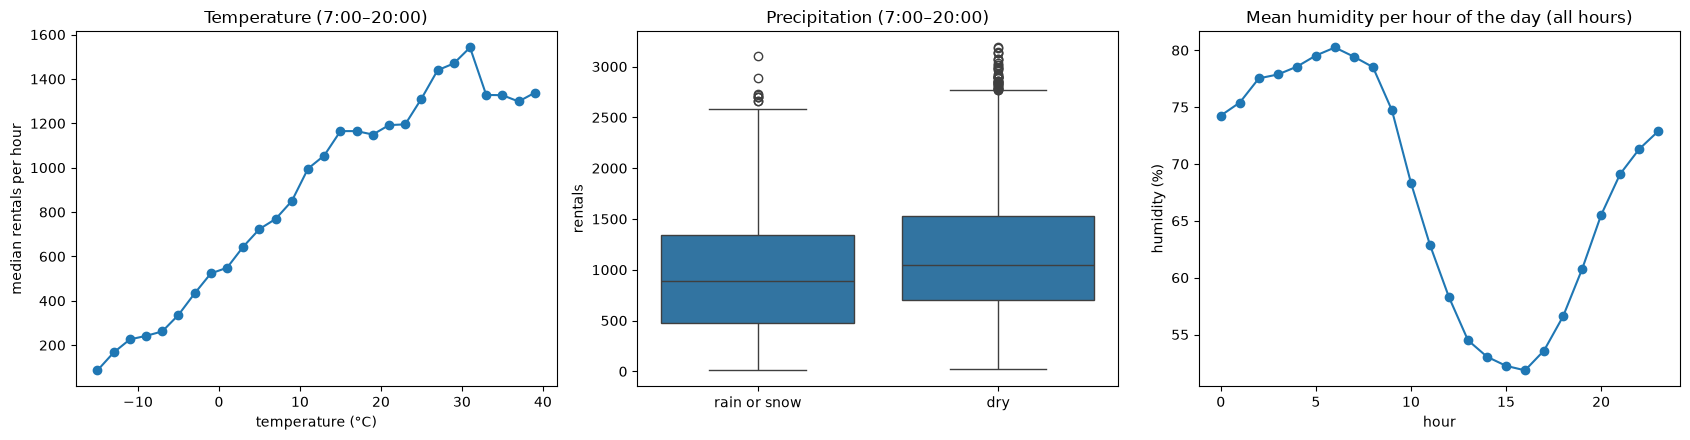

              count  median
wet                        
dry            6872  1048.0
rain or snow   1329   887.0


In [11]:
day = eda[eda["hour"].between(7, 20)].copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# temperature in 2-degree bins
day["temp_bin"] = pd.cut(day["temperature"], bins=range(-16, 42, 2))
temp = day.groupby("temp_bin", observed=True)["rentals"].median()
axes[0].plot([b.mid for b in temp.index], temp.values, marker="o")
axes[0].set_title("Temperature (7:00–20:00)")
axes[0].set_xlabel("temperature (°C)")
axes[0].set_ylabel("median rentals per hour")

# dry hours vs. hours with rain or snow
day["wet"] = np.where(day["precipitation"] > 0, "rain or snow", "dry")
sns.boxplot(data=day, x="wet", y="rentals", ax=axes[1])
axes[1].set_title("Precipitation (7:00–20:00)")
axes[1].set_xlabel("")

# humidity over the day: is it higher at night?
eda.groupby("hour")["humidity"].mean().plot(ax=axes[2], marker="o")
axes[2].set_title("Mean humidity per hour of the day (all hours)")
axes[2].set_ylabel("humidity (%)")

plt.tight_layout()
plt.show()

print(day.groupby("wet")["rentals"].agg(["count", "median"]))

**Findings:**
- **Temperature** is the strongest weather effect: median rentals rise steadily from ≈ 100 per hour at −15 °C to ≈ 1,500 at 30 °C, then drop again above ≈ 31 °C (too hot). That curve is not a straight line, which is why the correlation (≈ 0.48) understates it.
- **Rain or snow** lowers rentals (median 887 vs. 1,048 in dry daytime hours), although their correlation with rentals was close to 0: most hours are dry, and the effect is a jump between dry and wet, not a straight line.
- **Humidity** is highest at night and in the early morning (≈ 80 %) and lowest in the afternoon (≈ 52 %). Its negative correlation with rentals (−0.43) is mostly **the hour of the day in disguise**, not people avoiding humid air. It stays a feature, but the correlation should not be read as its effect.

**Is `weather_code` new information?** For each code, the ranges of the other weather columns:

In [12]:
df_train.groupby("weather_code")[["precipitation", "snowfall", "cloud_cover"]].agg(["min", "max"])

precipitation       snowfall       cloud_cover     
                       min   max      min   max         min  max
weather_code                                                    
0                      0.0   0.0     0.00  0.00           0   19
1                      0.0   0.0     0.00  0.00          20   49
2                      0.0   0.0     0.00  0.00          50   79
3                      0.0   0.0     0.00  0.00          80  100
51                     0.1   0.4     0.00  0.00           2  100
53                     0.5   0.9     0.00  0.00           3  100
55                     1.0   1.2     0.00  0.00           8  100
61                     1.3   2.4     0.00  0.00          32  100
63                     2.5   7.5     0.00  0.00          28  100
65                     7.7  13.6     0.00  0.00          84  100
71                     0.1   3.5     0.07  0.14          25  100
73                     0.3   2.8     0.21  0.77          99  100
75                     1.3   2.9     0.91  2.03         100  100

**Finding:** the ranges do not overlap. Codes 0–3 have no rain or snow and differ only by `cloud_cover` (0–19, 20–49, 50–79, 80–100 %). Drizzle and rain (51–65) are separated by the amount of `precipitation`, and snow (71–75) is every hour with `snowfall` above 0. So `weather_code` is a **binned version of `precipitation`, `snowfall` and `cloud_cover`**. Trees can learn the same thresholds from those columns directly, so `weather_code` is dropped.

### 4d. Redundant columns and leakage

Correlations between the numeric columns (lower triangle only, because the matrix is symmetric):

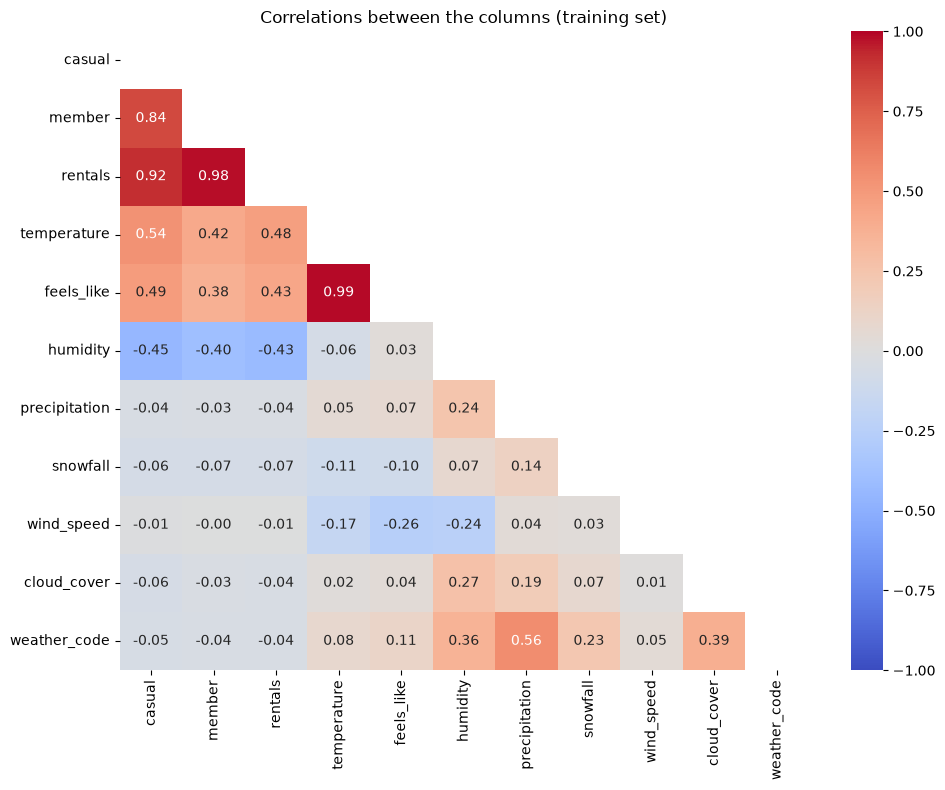

In [13]:
numeric = df_train.select_dtypes("number")
corr = numeric.corr()

# True for the upper triangle and the diagonal -> those cells get hidden
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlations between the columns (training set)")
plt.tight_layout()
plt.show()

- `temperature` and `feels_like` correlate at **0.99**: they are practically the same column. For `Ridge` that makes the coefficients unstable (collinearity), for trees it is only redundant. **Keep `temperature`** (stronger link to rentals, easier to explain), **drop `feels_like`**.
- `casual` and `member` correlate very strongly with `rentals`. That is suspicious, so check the leakage question: *would I know the value for an hour without having counted that hour's rentals?*

In [14]:
# do the two rider groups add up to the target?
same = df_train["casual"] + df_train["member"] == df_train["rentals"]
print(f"casual + member == rentals in {same.mean():.1%} of the hours")

casual + member == rentals in 100.0% of the hours


**Leakage:** `casual + member == rentals` in every hour. They are not features but **the target split into two parts**: you only know them after counting that hour's rentals. A model given them would just add them up and look perfect, but it could never be used for planning. **Drop `casual` and `member`.**

All other columns pass the check: the time comes from the calendar, and the weather can be known (or forecast) without counting rentals.

**Is there a difference between the two years?** The test hours are drawn from both years, so the year is a legitimate feature, if the level differs:

In [15]:
eda["year"] = eda["datetime"].dt.year
eda["month"] = eda["datetime"].dt.month
eda.groupby(["month", "year"])["rentals"].mean().round().unstack()

year,2024,2025,2026
month,,,
1,NaN,392.0,354.0
2,NaN,543.0,361.0
3,NaN,821.0,679.0
4,NaN,935.0,832.0
5,NaN,916.0,805.0
6,NaN,978.0,919.0
7,NaN,938.0,888.0
8,NaN,847.0,882.0
9,NaN,870.0,943.0


**Finding:** the season matters a lot (fewest rentals in January and February, most from April to October), and the same month can differ between years by 10–30 % (e.g. February 2025: 543 vs. February 2026: 361, probably a colder or snowier month). So `month` is a feature, and `year` is added too, so that the model can tell the two years apart.

### Record of manual changes and `prepare()`

Every change to the data by hand, collected in one function, so that exactly the same changes can be applied to the test set in step 8:

1. Drop the two hours that do not exist because of daylight saving time (second Sunday of March, 02:00).
2. New columns from `datetime`: `hour`, `weekday` (0 = Monday), `month`, `year`.
3. `is_holiday` = 1 if `holiday` is not NaN, else 0.
4. `is_working_day` = 1 for Monday–Friday that is not a holiday, else 0.
5. Drop `holiday` (replaced by the flag), `feels_like` (r = 0.99 with `temperature`), `weather_code` (derived from the other weather columns), and `casual` and `member` (**leakage**).

`datetime` stays in the DataFrame so that the date of each hour can be shown in step 8; it is only left out of `X`.

Scaling and one-hot encoding are **not** done here: they learn values from the data, so they go into the `Pipeline`, which learns them from the training folds only.

In [16]:
def prepare(data):
    """All manual changes to the data, collected in one place."""
    data = data.copy()
    dt = data["datetime"]

    # 1. the hour 02:00 on the second Sunday of March does not exist (clocks go forward)
    nonexistent = (dt.dt.month == 3) & (dt.dt.dayofweek == 6) & dt.dt.day.between(8, 14) & (dt.dt.hour == 2)
    data = data[~nonexistent]
    dt = data["datetime"]

    # 2. calendar features
    data["hour"] = dt.dt.hour
    data["weekday"] = dt.dt.dayofweek
    data["month"] = dt.dt.month
    data["year"] = dt.dt.year

    # 3. + 4. flags for holidays and working days
    data["is_holiday"] = data["holiday"].notna().astype(int)
    data["is_working_day"] = ((data["weekday"] < 5) & (data["is_holiday"] == 0)).astype(int)

    # 5. drop replaced, redundant and leaking columns
    return data.drop(columns=["holiday", "feels_like", "weather_code", "casual", "member"])


df_train_prep = prepare(df_train)
print(f"rows dropped: {len(df_train) - len(df_train_prep)}")
df_train_prep.head()

rows dropped: 2


,datetime,rentals,temperature,humidity,precipitation,snowfall,wind_speed,cloud_cover,hour,weekday,month,year,is_holiday,is_working_day
17440,2026-09-27 16:00:00,1035,16.7,87,0.5,0.0,20.3,100,16,6,9,2026,0,0
16867,2026-09-03 19:00:00,1826,30.4,67,0.0,0.0,7.7,47,19,3,9,2026,0,1
14851,2026-06-11 19:00:00,1661,31.7,60,0.0,0.0,9.1,97,19,3,6,2026,0,1
5446,2025-05-15 22:00:00,1001,20.8,93,0.0,0.0,5.4,7,22,3,5,2025,0,1
6025,2025-06-09 01:00:00,114,19.7,99,0.0,0.0,3.5,100,1,0,6,2025,0,1


## Step 5 – Features, target and two baselines

`X_train` holds the features, `y_train` the target. `datetime` is left out: the model gets the hour, weekday, month and year made from it instead.

In [17]:
X_train = df_train_prep.drop(columns=["rentals", "datetime"])
y_train = df_train_prep["rentals"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print(X_train.columns.tolist())

# the same five folds for every model, so the comparison is fair
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

X_train: (14014, 12)
y_train: (14014,)
['temperature', 'humidity', 'precipitation', 'snowfall', 'wind_speed', 'cloud_cover', 'hour', 'weekday', 'month', 'year', 'is_holiday', 'is_working_day']


**Mean baseline:** predicts the mean rentals of the training set for every hour. Every model has to beat this.

In [18]:
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

cv_dummy = -cross_val_score(dummy, X_train, y_train, cv=kfold, scoring="neg_root_mean_squared_error")

print(f"predicted rentals for every hour: {dummy.constant_[0][0]:.0f}")
print(f"CV RMSE: {cv_dummy.mean():.1f}")

predicted rentals for every hour: 753
CV RMSE: 636.2


**Rule-based baseline:** step 4b showed that the hour of the day and the type of day decide most of the pattern. The rule: *predict the mean rentals of the same hour on the same type of day (working day or not) in the training data.* That is a table of 2 × 24 numbers a person could look up by hand.

To compare it fairly with the models, its cross-validated RMSE is calculated with the same folds: the table is learned on four folds and checked on the fifth.

In [19]:
def learn_rule(X, y):
    """Mean rentals per hour and type of day: a 24 x 2 lookup table."""
    return y.groupby([X["hour"], X["is_working_day"]]).mean()


def rule_predict(X, table):
    keys = pd.MultiIndex.from_arrays([X["hour"], X["is_working_day"]])
    return table.reindex(keys).to_numpy()


# learn the rule on the whole training set
rule_table = learn_rule(X_train, y_train)

# cross-validated RMSE of the rule, with the same folds as the models
cv_rule = []
for train_idx, val_idx in kfold.split(X_train):
    table = learn_rule(X_train.iloc[train_idx], y_train.iloc[train_idx])
    pred = rule_predict(X_train.iloc[val_idx], table)
    cv_rule.append(root_mean_squared_error(y_train.iloc[val_idx], pred))
cv_rule = np.array(cv_rule)

print(f"CV RMSE: {cv_rule.mean():.1f}")
rule_table.unstack().round().head(10)

CV RMSE: 350.4


is_working_day,0,1
hour,,
0,408.0,135.0
1,280.0,66.0
2,177.0,35.0
3,90.0,22.0
4,50.0,40.0
5,73.0,144.0
6,157.0,395.0
7,282.0,868.0
8,487.0,1470.0


The **mean baseline** is off by **636 rentals** per hour (CV RMSE). The **rule** "mean of the same hour on the same type of day" brings that down to **350**: hour and type of day alone explain most of the pattern. Every model now has to beat **350**.

## Step 6 – Linear model and a single decision tree

**Preprocessing for Ridge:** `hour`, `weekday` and `month` are numbers, but for a linear model they are **categories**. As numbers, Ridge could only learn "one more hour = X more rentals", a straight line through the day, which cannot produce two peaks. One-hot encoding gives every hour its own coefficient. The other features are scaled, so that the regularisation treats all coefficients equally.

As in the King County project, `alpha` is tuned with `RandomizedSearchCV`.

In [20]:
categorical_features = ["hour", "weekday", "month"]
numeric_features = [col for col in X_train.columns if col not in categorical_features]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

ridge_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", Ridge()),
])

ridge_search = RandomizedSearchCV(
    ridge_pipe,
    param_distributions={"model__alpha": loguniform(1e-3, 1e3)},
    n_iter=20,
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
ridge_search.fit(X_train, y_train)
best_ridge = ridge_search.best_estimator_

print(f"best alpha: {ridge_search.best_params_['model__alpha']:.4f}")
print(f"CV RMSE: {-ridge_search.best_score_:.1f}")

best alpha: 0.3905
CV RMSE: 304.4


**Why is Ridge still so far off?** It adds up one effect per feature: the coefficient for "17:00" is the same on every day, and "working day" only shifts the whole day up or down. But step 4b showed that working days and weekends have a **different shape** (two peaks vs. one hump). Ridge cannot learn that, unless it gets an **interaction**: one category for every combination of hour and type of day (48 categories).

In [21]:
from sklearn.preprocessing import FunctionTransformer


# an extra column for Ridge only: the hour combined with the type of day, e.g. "17_1"
def add_hour_daytype(X):
    X = X.copy()
    X["hour_daytype"] = X["hour"].astype(str) + "_" + X["is_working_day"].astype(str)
    return X


preprocessor_inter = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features + ["hour_daytype"]),
])

ridge_inter_pipe = Pipeline([
    ("interaction", FunctionTransformer(add_hour_daytype)),
    ("prep", preprocessor_inter),
    ("model", Ridge()),
])

ridge_inter_search = RandomizedSearchCV(
    ridge_inter_pipe,
    param_distributions={"model__alpha": loguniform(1e-3, 1e3)},
    n_iter=20,
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
ridge_inter_search.fit(X_train, y_train)
best_ridge_inter = ridge_inter_search.best_estimator_

print(f"best alpha: {ridge_inter_search.best_params_['model__alpha']:.4f}")
print(f"CV RMSE: {-ridge_inter_search.best_score_:.1f}")

best alpha: 0.3905
CV RMSE: 244.0


The interaction is made inside the `Pipeline` with a `FunctionTransformer`, so it is applied to the test set automatically. It learns nothing from the data, so it could also have gone into `prepare()`; it sits in the pipeline because only Ridge needs it.

**The decision tree** gets the features as they are: no scaling and no one-hot encoding. A tree only asks questions like "is `hour` ≤ 6.5?", so the scale of a column does not matter, and it can split `hour` into any ranges it likes. It can also learn interactions by itself: a split on `is_working_day` followed by splits on `hour` gives each type of day its own daily curve.

`max_depth` and `min_samples_leaf` are tuned with `GridSearchCV`, as in W4D1.

In [22]:
tree_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    {"max_depth": [6, 8, 10, 12, 15, None], "min_samples_leaf": [1, 3, 5, 10, 20]},
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
tree_grid.fit(X_train, y_train)
best_tree = tree_grid.best_estimator_

print(f"best parameters: {tree_grid.best_params_}")
print(f"CV RMSE: {-tree_grid.best_score_:.1f}")

best parameters: {'max_depth': None, 'min_samples_leaf': 10}
CV RMSE: 202.0


**Comparison (CV RMSE):** Ridge 304 → Ridge with the hour × day type interaction 244 → decision tree **202**.

- **The tree handles the pattern over the day better.** It does not assume that effects simply add up: by splitting on `is_working_day` and then on `hour`, it builds a separate daily curve for each type of day, and in the same way it can learn "warm *and* dry *and* 17:00". Ridge only gets close once the interaction is built for it by hand, and it still cannot learn that, for example, rain matters more at rush hour than at night, or that the temperature curve bends above 30 °C.
- **Ridge beats the rule baseline** (304 vs. 350), because it also uses the weather and the season.
- **Preprocessing:** the tree needs **none**: no scaling (splits do not depend on the scale) and no one-hot encoding (it can cut `hour` into any ranges). Ridge needs both.
- The best tree has no depth limit but at least 10 hours per leaf (`min_samples_leaf=10`): that is the setting that stops it from memorising single hours.

## Step 7 – Ensembles

### Random forest

Many deep trees, each trained on a bootstrap sample of the rows and with a random subset of the features at every split; their predictions are averaged (W4D2). Averaging removes most of the variance of a single tree. Tuned with `RandomizedSearchCV`: `max_features` (how many features each split may look at) and `min_samples_leaf`.

In [23]:
rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    param_distributions={
        "max_features": uniform(0.3, 0.7),      # share of the features, between 0.3 and 1.0
        "min_samples_leaf": randint(1, 10),
        "max_depth": [None, 15, 25],
    },
    n_iter=10,
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    random_state=42,
)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_

print(f"best parameters: {rf_search.best_params_}")
print(f"CV RMSE: {-rf_search.best_score_:.1f}")

best parameters: {'max_depth': None, 'max_features': np.float64(0.602361513049481), 'min_samples_leaf': 1}
CV RMSE: 159.5


### XGBoost

Boosting builds the trees **one after another**: each new tree is fitted to the errors (residuals) the trees before it still make (W4D3). A small `learning_rate` with many trees learns slowly but generalises better; `subsample` and `colsample_bytree` add randomness like in the forest. `max_depth` here is much smaller than in the forest: boosting combines many weak trees.

In [24]:
xgb_search = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions={
        "n_estimators": randint(300, 1000),
        "learning_rate": loguniform(0.02, 0.2),
        "max_depth": randint(4, 9),
        "subsample": uniform(0.6, 0.4),
        "colsample_bytree": uniform(0.6, 0.4),
        "min_child_weight": randint(1, 10),
    },
    n_iter=15,
    cv=kfold,
    scoring="neg_root_mean_squared_error",
    random_state=42,
)
xgb_search.fit(X_train, y_train)
best_xgb = xgb_search.best_estimator_

print(f"best parameters: {xgb_search.best_params_}")
print(f"CV RMSE: {-xgb_search.best_score_:.1f}")

best parameters: {'colsample_bytree': np.float64(0.662397808134481), 'learning_rate': np.float64(0.022861967752626437), 'max_depth': 8, 'min_child_weight': 4, 'n_estimators': 963, 'subsample': np.float64(0.8603553891795411)}
CV RMSE: 140.9


### CatBoost: do categorical features help?

CatBoost can treat columns as categories itself (`cat_features`). `hour`, `weekday` and `month` are candidates. The same model is cross-validated twice, once with them as numbers and once as categories. As the tip in the task says, `cat_features` is passed to `.fit()` via `params`, not to the constructor.

In [25]:
catboost = CatBoostRegressor(iterations=1000, random_seed=42, verbose=0)

cv_cat_numeric = -cross_val_score(catboost, X_train, y_train, cv=kfold,
                                  scoring="neg_root_mean_squared_error")
cv_cat_categorical = -cross_val_score(catboost, X_train, y_train, cv=kfold,
                                      scoring="neg_root_mean_squared_error",
                                      params={"cat_features": categorical_features})

print(f"hour, weekday, month as numbers:    CV RMSE {cv_cat_numeric.mean():.1f}")
print(f"hour, weekday, month as categories: CV RMSE {cv_cat_categorical.mean():.1f}")

hour, weekday, month as numbers:    CV RMSE 142.5
hour, weekday, month as categories: CV RMSE 157.5


**Finding:** treating `hour`, `weekday` and `month` as categories makes CatBoost **worse** (157.5 vs. 142.5) and about ten times slower. As numbers, the trees can group neighbouring hours ("6 ≤ hour ≤ 9") in one split, and neighbouring hours do behave alike. As categories, CatBoost replaces each value with a target statistic computed on the rows seen so far (ordered target encoding, W4D3), which loses that order and is noisier. So `cat_features` does **not** help here, and the numeric version is used.

In [26]:
# the version that did better: without cat_features
best_cat = CatBoostRegressor(iterations=1000, random_seed=42, verbose=0)
best_cat.fit(X_train, y_train)

CatBoostRegressor(iterations=1000, loss_function='RMSE', random_seed=42, verbose=0)

### Combining models: voting and stacking

- **Voting** averages the predictions of the three strongest models with equal weights (a fixed rule).
- **Stacking** learns the combination: a `Ridge` is trained on the **out-of-fold** predictions of the three models (W4D4), so it learns how much to trust each one, from predictions on rows the models did not see.

The base models are the tuned forest, the tuned XGBoost and CatBoost.

In [27]:
base_models = [("rf", best_rf), ("xgb", best_xgb), ("cat", best_cat)]

voting = VotingRegressor(base_models)
cv_voting = -cross_val_score(voting, X_train, y_train, cv=kfold, scoring="neg_root_mean_squared_error")
print(f"Voting   CV RMSE: {cv_voting.mean():.1f}")

stacking = StackingRegressor(base_models, final_estimator=Ridge(), cv=kfold)
cv_stacking = -cross_val_score(stacking, X_train, y_train, cv=kfold, scoring="neg_root_mean_squared_error")
print(f"Stacking CV RMSE: {cv_stacking.mean():.1f}")

Voting   CV RMSE: 140.1
Stacking CV RMSE: 137.7


In [28]:
# fit both on the whole training set for step 8
voting.fit(X_train, y_train)
stacking.fit(X_train, y_train)

# how much does the stacking Ridge trust each base model?
print(dict(zip(["rf", "xgb", "cat"], stacking.final_estimator_.coef_.round(2))))

{'rf': np.float64(0.09), 'xgb': np.float64(0.55), 'cat': np.float64(0.38)}


### Model selection by cross-validated RMSE

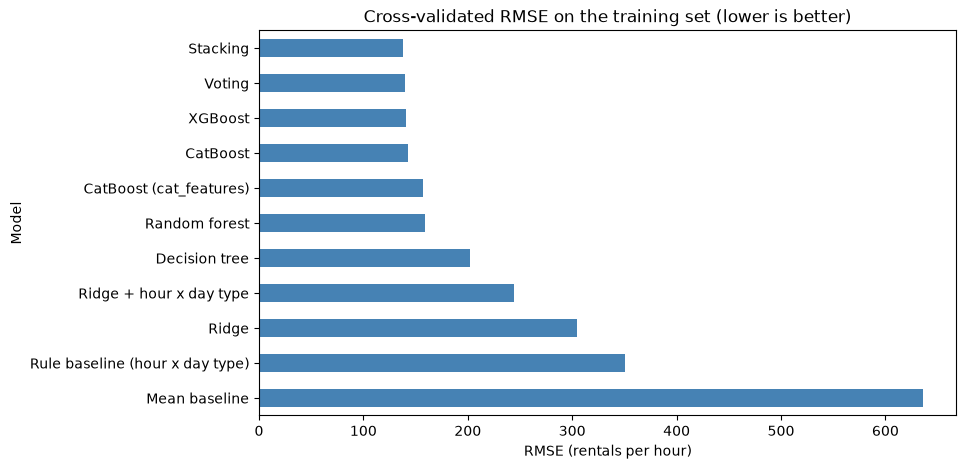

,CV RMSE
Model,
Stacking,137.7
Voting,140.1
XGBoost,140.9
CatBoost,142.5
CatBoost (cat_features),157.5
Random forest,159.5
Decision tree,202.0
Ridge + hour x day type,244.0
Ridge,304.4


In [29]:
cv_results = pd.DataFrame({
    "Model": ["Mean baseline", "Rule baseline (hour x day type)", "Ridge", "Ridge + hour x day type",
              "Decision tree", "Random forest", "XGBoost", "CatBoost", "CatBoost (cat_features)",
              "Voting", "Stacking"],
    "CV RMSE": [cv_dummy.mean(), cv_rule.mean(), -ridge_search.best_score_, -ridge_inter_search.best_score_,
                -tree_grid.best_score_, -rf_search.best_score_, -xgb_search.best_score_,
                cv_cat_numeric.mean(), cv_cat_categorical.mean(), cv_voting.mean(), cv_stacking.mean()],
}).set_index("Model").sort_values("CV RMSE")

fig, ax = plt.subplots(figsize=(9, 5))
cv_results["CV RMSE"].sort_values(ascending=False).plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Cross-validated RMSE on the training set (lower is better)")
ax.set_xlabel("RMSE (rentals per hour)")
plt.show()

cv_results.round(1)

**Model selection:** every ensemble is far better than the single tree (202), and the boosting models beat the random forest (≈ 141 vs. 160): boosting corrects the errors of the trees before it, while a forest only averages trees that all make similar errors.

The **stacking ensemble has the lowest CV RMSE (137.7)** and is chosen as the final model. Its gain over the best single model (XGBoost, 140.9) is small, about 2 %: the three base models make largely the same mistakes, so combining them can only remove a little. The Ridge on top trusts XGBoost most (weight 0.55), then CatBoost (0.38), and the forest hardly at all (0.09). If simplicity or speed mattered more, XGBoost alone would be almost as good.

## Step 8 – Test set and final evaluation

The test set is unlocked now. First the same manual changes as on the training set, with the same function:

In [30]:
df_test_prep = prepare(df_test)

X_test = df_test_prep.drop(columns=["rentals", "datetime"])
y_test = df_test_prep["rentals"]

print(f"rows dropped: {len(df_test) - len(df_test_prep)}")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

rows dropped: 0
X_test: (3504, 12)
y_test: (3504,)


Training and test scores of every model in one table. RMSE is the main metric; MAE and R² on the test set are added for context.

In [31]:
models = {
    "Mean baseline": dummy.predict,
    "Rule baseline (hour x day type)": lambda X: rule_predict(X, rule_table),
    "Ridge": best_ridge.predict,
    "Ridge + hour x day type": best_ridge_inter.predict,
    "Decision tree": best_tree.predict,
    "Random forest": best_rf.predict,
    "XGBoost": best_xgb.predict,
    "CatBoost": best_cat.predict,
    "Voting": voting.predict,
    "Stacking": stacking.predict,
}

rows = []
for name, predict in models.items():
    pred_train = predict(X_train)
    pred_test = predict(X_test)
    rows.append({
        "Model": name,
        "Train RMSE": root_mean_squared_error(y_train, pred_train),
        "CV RMSE": cv_results.loc[name, "CV RMSE"],
        "Test RMSE": root_mean_squared_error(y_test, pred_test),
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test R²": r2_score(y_test, pred_test),
    })

results = pd.DataFrame(rows).set_index("Model")
results.round({"Train RMSE": 1, "CV RMSE": 1, "Test RMSE": 1, "Test MAE": 1, "Test R²": 3})

,Train RMSE,CV RMSE,Test RMSE,Test MAE,Test R²
Model,,,,,
Mean baseline,636.2,636.2,628.7,521.0,-0.000
Rule baseline (hour x day type),348.8,350.4,342.8,232.3,0.703
Ridge,303.2,304.4,293.5,223.0,0.782
Ridge + hour x day type,242.4,244.0,239.3,178.5,0.855
Decision tree,148.3,202.0,184.9,114.2,0.913
Random forest,57.5,159.5,148.3,92.1,0.944
XGBoost,61.6,140.9,132.9,82.9,0.955
CatBoost,112.7,142.5,136.3,84.9,0.953
Voting,72.6,140.1,132.2,80.0,0.956


**Comparison of the models:**
- **All models beat both baselines** on the test set. The best one, stacking, has a test RMSE of **131 rentals** per hour (MAE 80, R² 0.957), compared with 343 for the rule and 629 for the mean.
- **Gain of each step** (test RMSE): rule 343 → Ridge 294 (−14 %) → Ridge with interaction 239 (−18 %) → decision tree 185 (−23 %) → random forest 148 (−20 %) → XGBoost 133 (−10 %) → stacking 131 (−2 %). The biggest jumps come from moving from a linear model to trees and from one tree to an ensemble; combining ensembles adds little.
- **Training vs. test scores:** the linear models and baselines score almost the same on both (they are too simple to overfit). The tree-based models are much better on the training data than on the test data, e.g. random forest 58 vs. 148, XGBoost 62 vs. 133: they partly memorise the training hours. That is why models are chosen by the **CV RMSE**, not the training RMSE. The CV and test RMSE agree closely for every model (the test is even slightly better), so cross-validation predicted the test performance well, and the ranking of the models is the same.

### Where does the best model make its biggest mistakes?

The analysis uses the model chosen by cross-validation, the **stacking ensemble**, and only the test hours: the model has seen the training hours, so its errors there are too small to tell anything.

**1. Residuals** = actual minus predicted rentals. Positive: the model predicted too few rentals; negative: too many.

In [32]:
pred_best = stacking.predict(X_test)
residuals = y_test - pred_best

# one table with everything needed for the analysis
analysis = df_test_prep.copy()
analysis["predicted"] = pred_best
analysis["residual"] = residuals
analysis["day_type"] = np.where(analysis["is_working_day"] == 1, "working day", "weekend/holiday")

print(f"predictions below 0: {(pred_best < 0).sum()} of {len(pred_best)} hours (lowest: {pred_best.min():.0f})")
analysis["residual"].describe().round(1)

predictions below 0: 81 of 3504 hours (lowest: -115)


count    3504.0
mean       -1.8
std       130.7
min     -1250.6
25%       -45.6
50%         3.6
75%        46.1
max       762.7
Name: residual, dtype: float64

**2. Plot the residuals:** against the predicted rentals, and by hour of the day.

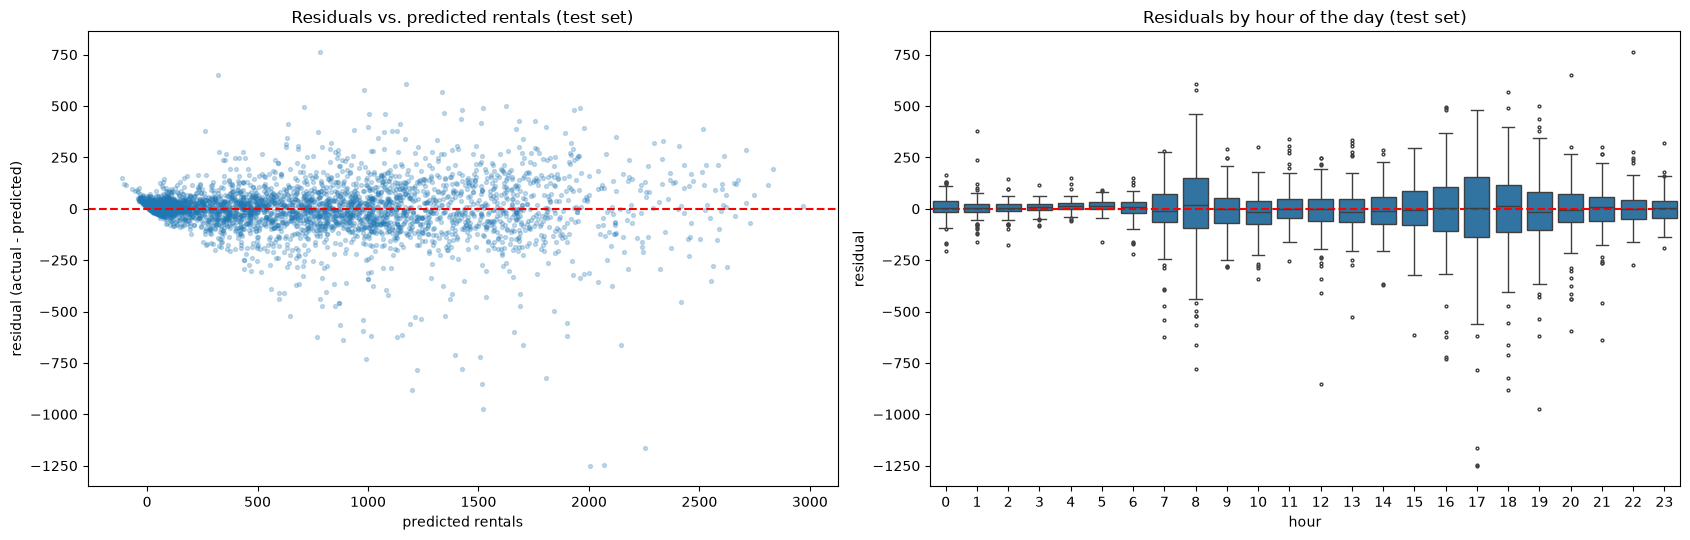

,hours,mean_error,mean_abs_error
predicted,,,
< 250,1007,11.6,27.0
250–500,521,-8.0,63.4
500–1000,858,-10.3,89.4
1000–1500,625,-4.4,112.6
1500–2000,369,1.8,140.2
> 2000,124,-23.2,166.7


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

axes[0].scatter(analysis["predicted"], analysis["residual"], alpha=0.25, s=8)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("predicted rentals")
axes[0].set_ylabel("residual (actual - predicted)")
axes[0].set_title("Residuals vs. predicted rentals (test set)")

sns.boxplot(data=analysis, x="hour", y="residual", ax=axes[1], fliersize=2)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals by hour of the day (test set)")

plt.tight_layout()
plt.show()

# does the size of the errors grow with the number of rentals?
size_range = pd.cut(analysis["predicted"], [-np.inf, 250, 500, 1000, 1500, 2000, np.inf],
                    labels=["< 250", "250–500", "500–1000", "1000–1500", "1500–2000", "> 2000"])
analysis.groupby(size_range, observed=True)["residual"].agg(
    hours="size", mean_error="mean", mean_abs_error=lambda r: r.abs().mean()
).round(1)

**Findings:**
- The residuals are centred on 0 (median ≈ 4), so the model is not biased up or down overall; but **81 of 3,504 predictions are below 0** (lowest −115), all in quiet hours. Negative rentals are impossible, so in practice the predictions should be clipped at 0.
- **The errors grow with the number of rentals:** the mean absolute error is ≈ 27 rentals when the model predicts fewer than 250, and ≈ 167 when it predicts more than 2,000. The scatter plot widens like a funnel. Relative to the size of the hour, the errors are similar; in absolute bikes, the busy hours are the hard ones.
- **By hour:** at night (0:00–6:00) the errors are tiny. The largest spread is at the **commuting peaks, 8:00 and 16:00–19:00**, where rentals are highest and most sensitive to the weather and to special days. The biggest single misses (up to −1,250) are evening rush hours where the model expected a normal busy hour.

**3. Predicted and actual rentals over the day**, separately for working days and weekends/holidays:

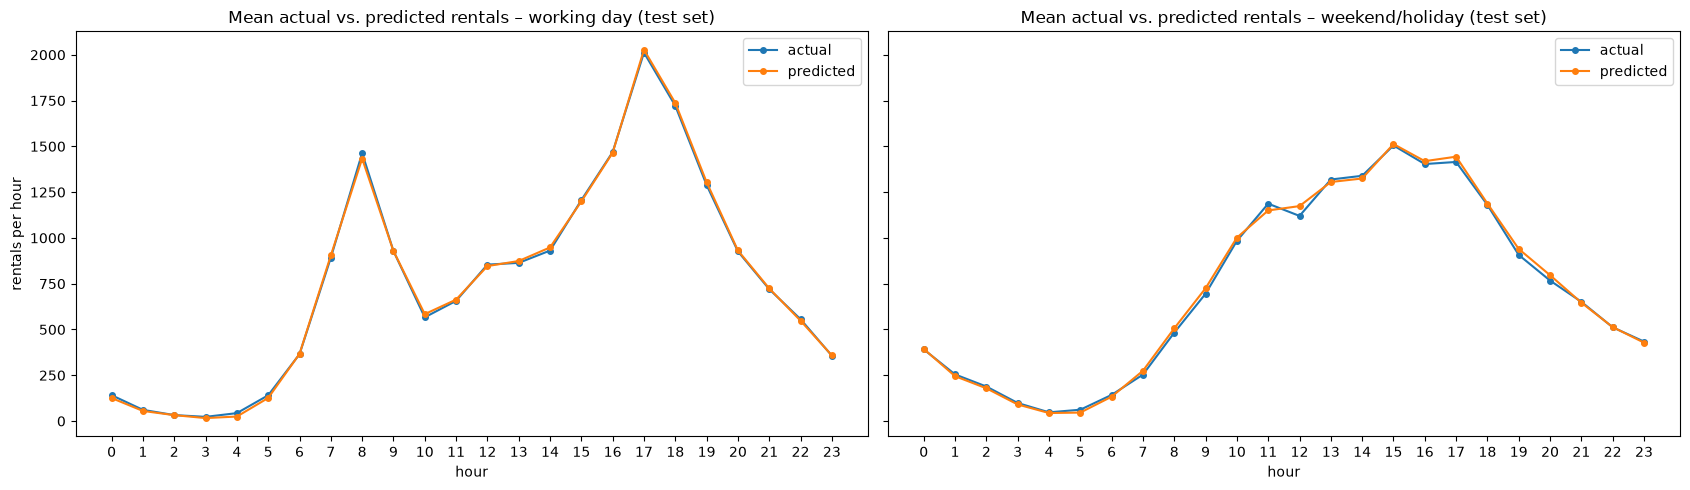

day_type,weekend/holiday,working day
hour,,
0,-2.7,15.5
1,9.5,6.0
2,9.6,0.3
3,8.0,6.6
4,3.8,18.7
5,15.6,14.5
6,9.7,-1.5
7,-20.7,-11.9
8,-23.4,29.7


In [34]:
by_hour = analysis.groupby(["day_type", "hour"])[["rentals", "predicted"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
for ax, day_type in zip(axes, ["working day", "weekend/holiday"]):
    by_hour.loc[day_type].plot(ax=ax, marker="o", markersize=4)
    ax.set_title(f"Mean actual vs. predicted rentals – {day_type} (test set)")
    ax.set_xticks(range(0, 24))
    ax.set_ylabel("rentals per hour")
    ax.legend(["actual", "predicted"])
plt.tight_layout()
plt.show()

# mean residual per hour: where does the model predict too many or too few on average?
mean_resid = analysis.groupby(["hour", "day_type"])["residual"].mean().unstack().round(1)
mean_resid

**Finding:** the model reproduces the daily pattern from step 4 almost exactly: the two commuting peaks on working days and the broad afternoon hump on weekends. The mean residual per hour stays within about ±55 rentals for every hour. The largest average deviations are on weekends and holidays around midday (11:00: +37, 12:00: −54), where there is less and noisier data. On weekends it also predicts slightly **too many** in the morning (7:00–9:00) and in the evening (17:00 and 19:00–20:00), about 20–30 rentals per hour on average; on working days the largest average deviations are a little too few at 8:00 (+30) and a little too many around 17:00–19:00 (≈ −15). These are small compared with the 130 RMSE: the big errors are single unusual hours, not a systematic problem with certain hours.

**4. The hours with the biggest mistakes**, with their date, time and weather:

In [35]:
show = ["datetime", "rentals", "predicted", "residual", "day_type",
        "temperature", "precipitation", "snowfall", "humidity", "wind_speed", "cloud_cover"]

# the original holiday name helps to explain the errors
analysis["holiday"] = df_test.loc[analysis.index, "holiday"]
show = show + ["holiday"]

# round the numbers for display only (the datetime column cannot be rounded)
table = analysis[show].round({"predicted": 0, "residual": 0})

print("10 hours with the largest POSITIVE residuals (model predicted far too few):")
display(table.sort_values("residual", ascending=False).head(10))

print("10 hours with the largest NEGATIVE residuals (model predicted far too many):")
display(table.sort_values("residual").head(10))

10 hours with the largest POSITIVE residuals (model predicted far too few):


,datetime,rentals,predicted,residual,day_type,temperature,precipitation,snowfall,humidity,wind_speed,cloud_cover,holiday
15334,2026-07-01 22:00:00,1546,783.0,763.0,working day,30.3,0.0,0.0,70,5.6,13,NaN
15452,2026-07-06 20:00:00,973,321.0,652.0,working day,24.4,5.3,0.0,95,6.3,100,NaN
1688,2024-12-10 08:00:00,1775,1170.0,605.0,working day,3.9,0.0,0.0,100,5.4,100,NaN
1544,2024-12-04 08:00:00,1562,984.0,578.0,working day,-3.2,0.0,0.0,80,3.2,17,NaN
15450,2026-07-06 18:00:00,1901,1333.0,568.0,working day,25.6,1.8,0.0,92,1.6,100,NaN
15331,2026-07-01 19:00:00,2127,1625.0,502.0,working day,34.4,0.1,0.0,50,8.5,23,NaN
13816,2026-04-29 16:00:00,1209,712.0,497.0,working day,14.8,1.7,0.0,93,11.7,100,NaN
6930,2025-07-16 18:00:00,2451,1958.0,493.0,working day,26.9,0.0,0.0,82,9.5,100,NaN
15568,2026-07-11 16:00:00,2013,1522.0,491.0,weekend/holiday,25.5,0.4,0.0,81,4.6,98,NaN
13505,2026-04-16 17:00:00,2415,1934.0,481.0,weekend/holiday,34.4,0.0,0.0,24,15.7,5,DC Emancipation Day


10 hours with the largest NEGATIVE residuals (model predicted far too many):


,datetime,rentals,predicted,residual,day_type,temperature,precipitation,snowfall,humidity,wind_speed,cloud_cover,holiday
6281,2025-06-19 17:00:00,756,2007.0,-1251.0,weekend/holiday,28.4,0.0,0.0,69,8.7,30,Juneteenth National Independence Day
15209,2026-06-26 17:00:00,825,2070.0,-1245.0,working day,26.5,1.5,0.0,69,15.2,99,NaN
10121,2025-11-26 17:00:00,1090,2252.0,-1162.0,working day,19.1,0.0,0.0,57,11.4,24,NaN
5803,2025-05-30 19:00:00,548,1521.0,-973.0,working day,20.8,1.1,0.0,79,11.8,100,NaN
2202,2024-12-31 18:00:00,320,1200.0,-880.0,working day,11.4,0.3,0.0,75,11.1,100,NaN
16092,2026-08-02 12:00:00,666,1518.0,-852.0,weekend/holiday,28.0,0.0,0.0,69,13.7,98,NaN
12858,2026-03-20 18:00:00,983,1806.0,-823.0,working day,19.5,0.1,0.0,42,16.7,100,NaN
10961,2025-12-31 17:00:00,438,1222.0,-784.0,working day,2.6,0.0,0.0,40,10.7,99,NaN
14456,2026-05-26 08:00:00,645,1425.0,-780.0,working day,19.3,0.3,0.0,96,3.6,100,NaN
16096,2026-08-02 16:00:00,260,989.0,-729.0,weekend/holiday,24.0,4.4,0.0,98,7.8,100,NaN


**What the biggest mistakes have in common:**
- **Too many predicted (negative residuals): special days and sudden weather.**
  - *Special days that are not public holidays:* New Year's Eve evening (31 December 2024 18:00, 31 December 2025 17:00) and the day before Thanksgiving (26 November 2025, 17:00), when many people have left town or finish early. The data only flags official holidays.
  - *A holiday on a weekday:* Juneteenth 2025 (Thursday, 17:00): 756 actual vs. 2,007 predicted. There are only ~20 holiday days to learn from, so the model still expects a lot of traffic in the late afternoon. On top of that, it rained heavily at 16:00 and 18:00 that day.
  - *Rain just before or around the hour:* 2 August 2026 (12:00 and 16:00) had showers on and off all day. The model only sees the rain **in** the hour; if the hour itself is dry but it poured just before, it expects normal traffic.
- **Too few predicted (positive residuals): unusual evenings and busy rush hours.**
  - Evenings in early July 2026 that were much busier than usual: 1 July at 22:00 (1,546 actual vs. 783 predicted, a sudden jump late in the evening) and 6 July at 18:00 and 20:00, which stayed busy despite heavy rain. Most likely **events** (concerts, sports, celebrations around 4 July) that the data does not know about.
  - Rush hours that were busier than the weather suggests, e.g. working-day mornings in December 2024 (8:00 on 4 and 10 December, cold but dry).
  - *A holiday that most people work on:* DC Emancipation Day (16 April 2026, 17:00) is a holiday only in Washington, D.C.; federal and many other employees still commute, so treating it like a Sunday predicts too few. Holidays can go wrong in both directions.
- The autumn hours with two hours added together (01:00 in November) do not appear among the biggest errors.

## Conclusion for the operations team

- **Model:** a stacking ensemble of a random forest, XGBoost and CatBoost, combined by a Ridge. On hours it has never seen, it is off by **≈ 80 rentals per hour typically (MAE)** and has an RMSE of **≈ 131**, compared with 343 for a simple lookup table by hour and type of day. It explains about 96 % of the variation in hourly rentals.
- **What drives rentals:** the hour of the day and the type of day (commuting peaks on working days, one afternoon hump on weekends), then temperature (more rentals up to ≈ 30 °C, fewer above), rain, and the season.
- **When to trust it:** ordinary hours, especially at night and in the middle of the day, where the errors are small. Its daily pattern matches reality closely for both working days and weekends.
- **When to be careful:**
  - **Rush hours** (8:00 and 16:00–19:00) have the largest errors in absolute bikes, so plan some buffer there.
  - **Special days that are not public holidays** (New Year's Eve, the day before Thanksgiving) and **holidays on weekdays**: the model expects too much traffic.
  - **Events** (concerts, sports, celebrations): the model cannot know about them and expects too little traffic.
  - **Showery days**: the model reacts to rain only in the same hour.
- **Possible improvements:** flags for special days (New Year's Eve, the day before Thanksgiving), an events calendar, the rain of the previous hour as a feature, clipping negative predictions at 0, and a time-based check (train on the past, test on the most recent months) if the model is ever used to forecast future dates.